# 서울 상권정보 분석

---
## 1단계: 라이브러리 불러오기 및 환경 설정

분석에 필요한 도구(라이브러리)를 먼저 불러옵니다.


In [1]:
import pandas as pd          
import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
plt.rc('font', family='Malgun Gothic')
plt.rc('axes', unicode_minus=False)

---
## 2단계: 데이터 불러오기

CSV 파일을 DataFrame으로 불러옵니다.

```
pd.read_csv('파일경로', encoding='인코딩방식')
```

- `encoding='utf-8'` 또는  `'cp949'` 등 한글이 포함된 파일을 제대로 읽기 위한 설정

In [3]:
df = pd.read_csv('소상공인시장진흥공단_상가(상권)정보_서울_202606.csv', encoding='utf-8')  # 여러분이 공공데이터에서 다운 받은 데이터파일, 없으면 사캠 데이터로 하세요!
df.head()

,상가업소번호,상호명,지점명,상권업종대분류코드,상권업종대분류명,상권업종중분류코드,상권업종중분류명,상권업종소분류코드,상권업종소분류명,표준산업분류코드,...,건물관리번호,건물명,도로명주소,구우편번호,신우편번호,동정보,층정보,호정보,경도,위도
0,MA0106202201A2069228,쥬씨&고망고,서울숲점,G2,소매,G221,기타 상품 소매,G22199,그 외 기타 상품 전문 소매업,G47859,...,1120011400106560297008039,NaN,서울특별시 성동구 왕십리로 114,133823,4778,NaN,NaN,NaN,127.044744,37.547680
1,MA0106202201A1955471,루42,홍대점,G2,소매,G215,의약·화장품 소매,G21503,화장품 소매업,G47813,...,1144012000103580018010221,NaN,서울특별시 마포구 홍익로 5-1,121838,4040,NaN,NaN,NaN,126.923610,37.553115
2,MA0106202201A0016575,언더아머,코리아,G2,소매,G213,오락용품 소매,G21304,운동용품 소매업,G47631,...,1168010100108090018022735,NaN,서울특별시 강남구 강남대로 464,135931,6123,NaN,NaN,NaN,127.025322,37.503708
3,MA0106202201A1284924,세일50,NaN,G2,소매,G209,섬유·의복·신발 소매,G20908,가발 소매업,G47422,...,1111013600100150000014714,NaN,서울특별시 종로구 인사동길 24,110290,3163,NaN,NaN,NaN,126.986518,37.572952
4,MA0106202201A2215148,씨제이올리브영공릉역점,NaN,G2,소매,G221,기타 상품 소매,G22199,그 외 기타 상품 전문 소매업,G47859,...,1135010300104410092014465,NaN,서울특별시 노원구 동일로192길 74,139804,1834,NaN,NaN,NaN,127.077088,37.627077


In [4]:
df.shape

(554092, 39)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 554092 entries, 0 to 554091
Data columns (total 39 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   상가업소번호     554092 non-null  str    
 1   상호명        554092 non-null  str    
 2   지점명        51858 non-null   str    
 3   상권업종대분류코드  554092 non-null  str    
 4   상권업종대분류명   554092 non-null  str    
 5   상권업종중분류코드  554092 non-null  str    
 6   상권업종중분류명   554092 non-null  str    
 7   상권업종소분류코드  554092 non-null  str    
 8   상권업종소분류명   554092 non-null  str    
 9   표준산업분류코드   553900 non-null  str    
 10  표준산업분류명    553900 non-null  str    
 11  시도코드       554092 non-null  int64  
 12  시도명        554092 non-null  str    
 13  시군구코드      554092 non-null  int64  
 14  시군구명       554092 non-null  str    
 15  행정동코드      554092 non-null  int64  
 16  행정동명       554092 non-null  str    
 17  법정동코드      554092 non-null  int64  
 18  법정동명       554092 non-null  str    
 19  지번코드       554092 non-null  int64 

- 이번 분석에서 주로 사용할 핵심 열들만 선택

In [6]:
cols = ['상가업소번호', '상호명','상권업종대분류명','상권업종중분류명',
        '상권업종소분류명', '시군구명', '행정동명', '법정동명', '경도', '위도']

In [7]:
df = df[cols]

In [8]:
df.head()

,상가업소번호,상호명,상권업종대분류명,상권업종중분류명,상권업종소분류명,시군구명,행정동명,법정동명,경도,위도
0,MA0106202201A2069228,쥬씨&고망고,소매,기타 상품 소매,그 외 기타 상품 전문 소매업,성동구,성수1가2동,성수동1가,127.044744,37.547680
1,MA0106202201A1955471,루42,소매,의약·화장품 소매,화장품 소매업,마포구,서교동,서교동,126.923610,37.553115
2,MA0106202201A0016575,언더아머,소매,오락용품 소매,운동용품 소매업,강남구,역삼1동,역삼동,127.025322,37.503708
3,MA0106202201A1284924,세일50,소매,섬유·의복·신발 소매,가발 소매업,종로구,종로1.2.3.4가동,인사동,126.986518,37.572952
4,MA0106202201A2215148,씨제이올리브영공릉역점,소매,기타 상품 소매,그 외 기타 상품 전문 소매업,노원구,공릉2동,공릉동,127.077088,37.627077


In [9]:
df.columns

Index(['상가업소번호', '상호명', '상권업종대분류명', '상권업종중분류명', '상권업종소분류명', '시군구명', '행정동명',
       '법정동명', '경도', '위도'],
      dtype='str')

---
## 3단계: 결측치(빈 값) 확인 및 처리

데이터에 비어있는 값(NaN: Not a Number)이 있는지 확인합니다.

- `isnull()`: 각 값이 빈 값인지 True/False로 반환
- `sum()`: True를 1로 계산해서 열별 결측치 개수를 합산

In [10]:
df.isnull().sum()

상가업소번호      0
상호명         0
상권업종대분류명    0
상권업종중분류명    0
상권업종소분류명    0
시군구명        0
행정동명        0
법정동명        0
경도          0
위도          0
dtype: int64

---
## 4단계: 업종 대분류 분석

서울의 상가들이 어떤 업종으로 이루어져 있는지 파악합니다.

### 핵심 함수
- `unique()`: 중복 없는 고유한 값 목록 반환
- `value_counts()`: 각 값의 등장 횟수 반환 (많은 순서대로 정렬)

In [11]:
df['상권업종대분류명'].unique()

<StringArray>
['소매', '예술·스포츠', '음식', '교육', '수리·개인', '시설관리·임대', '과학·기술', '숙박', '부동산', '보건의료']
Length: 10, dtype: str

In [12]:
df['상권업종대분류명'].nunique()

10

In [13]:
df['상권업종대분류명'].value_counts()

상권업종대분류명
음식         141126
소매         111306
과학·기술      100549
수리·개인       53716
교육          44215
시설관리·임대     26296
부동산         24714
예술·스포츠      21061
보건의료        18700
숙박          12409
Name: count, dtype: int64

In [14]:
counts = df['상권업종대분류명'].value_counts()

In [15]:
counts.index

Index(['음식', '소매', '과학·기술', '수리·개인', '교육', '시설관리·임대', '부동산', '예술·스포츠', '보건의료',
       '숙박'],
      dtype='str', name='상권업종대분류명')

In [16]:
counts.values

array([141126, 111306, 100549,  53716,  44215,  26296,  24714,  21061,
        18700,  12409])

<Axes: xlabel='상권업종대분류명'>

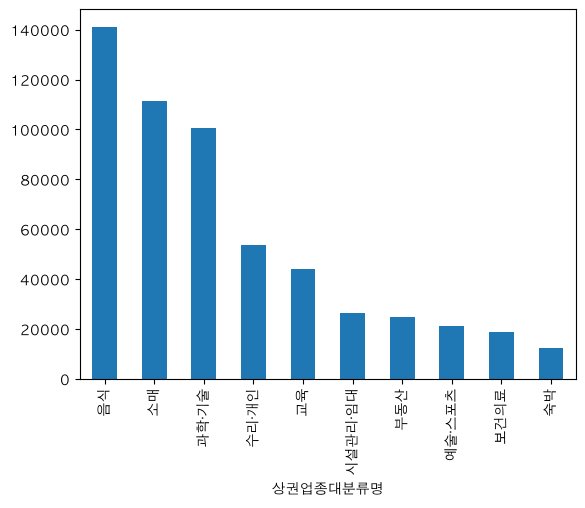

In [17]:
counts.plot(kind='bar')

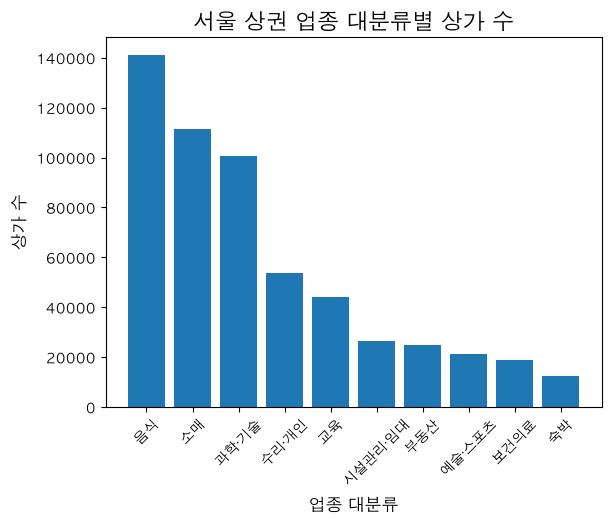

In [18]:
#plt.figure(figsize=(12, 5))          # 그래프 크기 설정 (가로12, 세로5)
plt.bar(  counts.index , counts.values  )
plt.title('서울 상권 업종 대분류별 상가 수', fontsize=16)
plt.xlabel('업종 대분류', fontsize=12)
plt.ylabel('상가 수', fontsize=12)
plt.xticks(rotation=45)  # x축 눈금을 45도 기울여서 표시
plt.show()

<Axes: >

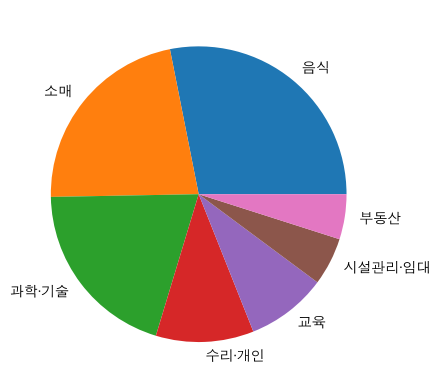

In [19]:
df['상권업종대분류명'].value_counts().head(7).plot(kind='pie')

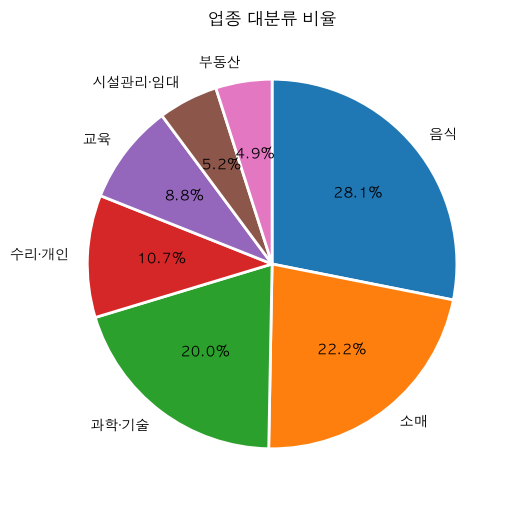

In [20]:
df['상권업종대분류명'].value_counts().head(7).plot(
    kind='pie',
    figsize=(6, 6),
    autopct='%1.1f%%',        # 퍼센트 표시
    startangle=90,            # 시작 각도
    counterclock=False,       # 시계 방향
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}  # 경계선
)

plt.title('업종 대분류 비율')
plt.ylabel('')  # 불필요한 y축 제거
plt.show()

---
## loc / iloc 사용법

pandas에서 데이터를 선택하는 세 가지 방법을 비교합니다.

> 조건식     
> 라벨(이름)    
> 숫자 위치(번호)    


### loc - 라벨(이름) 기준으로 선택  (label-based location)

- 행: 인덱스 번호 또는 True/False 조건
- 열: 열 이름(문자열)
- **슬라이싱 시 끝 값 포함** (iloc과 다름!)

---

문제 : 인덱스 이름이 3인 행

In [21]:
df.loc[3]

상가업소번호      MA0106202201A1284924
상호명                         세일50
상권업종대분류명                      소매
상권업종중분류명             섬유·의복·신발 소매
상권업종소분류명                  가발 소매업
시군구명                         종로구
행정동명                 종로1.2.3.4가동
법정동명                         인사동
경도                    126.986518
위도                     37.572952
Name: 3, dtype: object

In [22]:
df.loc[3, '상호명']

'세일50'

In [23]:
df.loc[3, ['상호명', '시군구명']]

상호명     세일50
시군구명     종로구
Name: 3, dtype: str

In [24]:
df.loc[0:3]

,상가업소번호,상호명,상권업종대분류명,상권업종중분류명,상권업종소분류명,시군구명,행정동명,법정동명,경도,위도
0,MA0106202201A2069228,쥬씨&고망고,소매,기타 상품 소매,그 외 기타 상품 전문 소매업,성동구,성수1가2동,성수동1가,127.044744,37.547680
1,MA0106202201A1955471,루42,소매,의약·화장품 소매,화장품 소매업,마포구,서교동,서교동,126.923610,37.553115
2,MA0106202201A0016575,언더아머,소매,오락용품 소매,운동용품 소매업,강남구,역삼1동,역삼동,127.025322,37.503708
3,MA0106202201A1284924,세일50,소매,섬유·의복·신발 소매,가발 소매업,종로구,종로1.2.3.4가동,인사동,126.986518,37.572952


In [25]:
df.loc[0:3, '상호명':'상권업종소분류명']

,상호명,상권업종대분류명,상권업종중분류명,상권업종소분류명
0,쥬씨&고망고,소매,기타 상품 소매,그 외 기타 상품 전문 소매업
1,루42,소매,의약·화장품 소매,화장품 소매업
2,언더아머,소매,오락용품 소매,운동용품 소매업
3,세일50,소매,섬유·의복·신발 소매,가발 소매업


### iloc - 숫자 위치(번호) 기준으로 선택 (iloc = integer location)

- 행/열 모두 **숫자 인덱스**로 지정
- **슬라이싱 시 끝 값 미포함** (Python 리스트와 동일)
- 열 이름을 몰라도 번호로 접근 가능

In [26]:
df.iloc[3]

상가업소번호      MA0106202201A1284924
상호명                         세일50
상권업종대분류명                      소매
상권업종중분류명             섬유·의복·신발 소매
상권업종소분류명                  가발 소매업
시군구명                         종로구
행정동명                 종로1.2.3.4가동
법정동명                         인사동
경도                    126.986518
위도                     37.572952
Name: 3, dtype: object

In [27]:
df.iloc[3, 1]

'세일50'

In [28]:
df.iloc[0:3]

,상가업소번호,상호명,상권업종대분류명,상권업종중분류명,상권업종소분류명,시군구명,행정동명,법정동명,경도,위도
0,MA0106202201A2069228,쥬씨&고망고,소매,기타 상품 소매,그 외 기타 상품 전문 소매업,성동구,성수1가2동,성수동1가,127.044744,37.547680
1,MA0106202201A1955471,루42,소매,의약·화장품 소매,화장품 소매업,마포구,서교동,서교동,126.923610,37.553115
2,MA0106202201A0016575,언더아머,소매,오락용품 소매,운동용품 소매업,강남구,역삼1동,역삼동,127.025322,37.503708


In [29]:
df.iloc[0:3, 1:5]

,상호명,상권업종대분류명,상권업종중분류명,상권업종소분류명
0,쥬씨&고망고,소매,기타 상품 소매,그 외 기타 상품 전문 소매업
1,루42,소매,의약·화장품 소매,화장품 소매업
2,언더아머,소매,오락용품 소매,운동용품 소매업


In [30]:
df.iloc[-1]

상가업소번호      MA0101202512A0013622
상호명                         드리머스
상권업종대분류명                   과학·기술
상권업종중분류명                      광고
상권업종소분류명                  광고 대행업
시군구명                         강서구
행정동명                        발산1동
법정동명                         마곡동
경도                    126.832179
위도                      37.55867
Name: 554091, dtype: object

문제 : 상권업종대분류명이 음식인 데이터 선택 

In [31]:
df['상권업종대분류명'] == '음식'

0         False
1         False
2         False
3         False
4         False
          ...  
554087    False
554088    False
554089    False
554090    False
554091    False
Name: 상권업종대분류명, Length: 554092, dtype: bool

In [32]:
df[ df['상권업종대분류명'] == '음식' ]

,상가업소번호,상호명,상권업종대분류명,상권업종중분류명,상권업종소분류명,시군구명,행정동명,법정동명,경도,위도
7,MA0106202201A0146032,위드유용산카페,음식,한식,백반/한정식,용산구,한강로동,한강로3가,126.963517,37.523789
9,MA0106202201A0153109,커피빈마리오아울렛점,음식,비알코올,카페,금천구,가산동,가산동,126.886479,37.478717
15,MA0106202201A0635239,수일통상,음식,한식,백반/한정식,송파구,가락2동,가락동,127.125664,37.492535
17,MA0106202201A0604674,할리스커피한남순천향점,음식,비알코올,카페,용산구,한남동,한남동,127.004978,37.533210
19,MA0106202201A0955263,씨제이푸드빌더플레이스다이닝&BBIS,음식,한식,백반/한정식,용산구,용산2가동,용산동2가,126.987869,37.551121
...,...,...,...,...,...,...,...,...,...,...
554072,MA0101202601A0010280,약속,음식,주점,생맥주 전문,구로구,개봉3동,개봉동,126.856671,37.487568
554073,MA0101202603A0020276,수행밀면,음식,한식,냉면/밀면,도봉구,도봉2동,도봉동,127.045218,37.676233
554077,MA0101202602A0024673,장가호떡,음식,기타 간이,그 외 기타 간이 음식점,송파구,위례동,장지동,127.143764,37.478621
554084,MA0101202512A0002478,천라쿵푸,음식,중식,중국집,은평구,대조동,대조동,126.920332,37.613948


In [33]:
df.loc[ df['상권업종대분류명'] == '음식' ]

,상가업소번호,상호명,상권업종대분류명,상권업종중분류명,상권업종소분류명,시군구명,행정동명,법정동명,경도,위도
7,MA0106202201A0146032,위드유용산카페,음식,한식,백반/한정식,용산구,한강로동,한강로3가,126.963517,37.523789
9,MA0106202201A0153109,커피빈마리오아울렛점,음식,비알코올,카페,금천구,가산동,가산동,126.886479,37.478717
15,MA0106202201A0635239,수일통상,음식,한식,백반/한정식,송파구,가락2동,가락동,127.125664,37.492535
17,MA0106202201A0604674,할리스커피한남순천향점,음식,비알코올,카페,용산구,한남동,한남동,127.004978,37.533210
19,MA0106202201A0955263,씨제이푸드빌더플레이스다이닝&BBIS,음식,한식,백반/한정식,용산구,용산2가동,용산동2가,126.987869,37.551121
...,...,...,...,...,...,...,...,...,...,...
554072,MA0101202601A0010280,약속,음식,주점,생맥주 전문,구로구,개봉3동,개봉동,126.856671,37.487568
554073,MA0101202603A0020276,수행밀면,음식,한식,냉면/밀면,도봉구,도봉2동,도봉동,127.045218,37.676233
554077,MA0101202602A0024673,장가호떡,음식,기타 간이,그 외 기타 간이 음식점,송파구,위례동,장지동,127.143764,37.478621
554084,MA0101202512A0002478,천라쿵푸,음식,중식,중국집,은평구,대조동,대조동,126.920332,37.613948


In [34]:
df.loc[ df['상권업종대분류명'] == '음식' , '상호명']

7                     위드유용산카페
9                  커피빈마리오아울렛점
15                       수일통상
17                할리스커피한남순천향점
19        씨제이푸드빌더플레이스다이닝&BBIS
                 ...         
554072                     약속
554073                   수행밀면
554077                   장가호떡
554084                   천라쿵푸
554085                     모담
Name: 상호명, Length: 141126, dtype: str

In [35]:
df.loc[ df['상권업종대분류명'] == '음식' , ['상호명', '상권업종중분류명']]

,상호명,상권업종중분류명
7,위드유용산카페,한식
9,커피빈마리오아울렛점,비알코올
15,수일통상,한식
17,할리스커피한남순천향점,비알코올
19,씨제이푸드빌더플레이스다이닝&BBIS,한식
...,...,...
554072,약속,주점
554073,수행밀면,한식
554077,장가호떡,기타 간이
554084,천라쿵푸,중식


In [36]:
len( df.loc[ df['상권업종대분류명'] == '음식' ] )

141126

---
## 5단계: 음식 업종 중분류 분석

대분류 중 '음식' 카테고리 안에서 어떤 세부 업종이 많은지 분석합니다.

### 데이터 필터링 방법
```python
df[조건]           # 조건에 맞는 행만 선택
df.loc[조건, 열]   # 조건에 맞는 행의 특정 열만 선택
```

1. 조건 만들기: 상권업종대분류명이 '음식'인지 True/False로 반환

In [37]:
df['상권업종대분류명'] == '음식'

0         False
1         False
2         False
3         False
4         False
          ...  
554087    False
554088    False
554089    False
554090    False
554091    False
Name: 상권업종대분류명, Length: 554092, dtype: bool

2. 조건에 맞는 데이터만 필터링하여 음식 업종만 보기

In [38]:
df[ df['상권업종대분류명'] == '음식' ]

,상가업소번호,상호명,상권업종대분류명,상권업종중분류명,상권업종소분류명,시군구명,행정동명,법정동명,경도,위도
7,MA0106202201A0146032,위드유용산카페,음식,한식,백반/한정식,용산구,한강로동,한강로3가,126.963517,37.523789
9,MA0106202201A0153109,커피빈마리오아울렛점,음식,비알코올,카페,금천구,가산동,가산동,126.886479,37.478717
15,MA0106202201A0635239,수일통상,음식,한식,백반/한정식,송파구,가락2동,가락동,127.125664,37.492535
17,MA0106202201A0604674,할리스커피한남순천향점,음식,비알코올,카페,용산구,한남동,한남동,127.004978,37.533210
19,MA0106202201A0955263,씨제이푸드빌더플레이스다이닝&BBIS,음식,한식,백반/한정식,용산구,용산2가동,용산동2가,126.987869,37.551121
...,...,...,...,...,...,...,...,...,...,...
554072,MA0101202601A0010280,약속,음식,주점,생맥주 전문,구로구,개봉3동,개봉동,126.856671,37.487568
554073,MA0101202603A0020276,수행밀면,음식,한식,냉면/밀면,도봉구,도봉2동,도봉동,127.045218,37.676233
554077,MA0101202602A0024673,장가호떡,음식,기타 간이,그 외 기타 간이 음식점,송파구,위례동,장지동,127.143764,37.478621
554084,MA0101202512A0002478,천라쿵푸,음식,중식,중국집,은평구,대조동,대조동,126.920332,37.613948


In [39]:
df.loc[df['상권업종대분류명'] == '음식']

,상가업소번호,상호명,상권업종대분류명,상권업종중분류명,상권업종소분류명,시군구명,행정동명,법정동명,경도,위도
7,MA0106202201A0146032,위드유용산카페,음식,한식,백반/한정식,용산구,한강로동,한강로3가,126.963517,37.523789
9,MA0106202201A0153109,커피빈마리오아울렛점,음식,비알코올,카페,금천구,가산동,가산동,126.886479,37.478717
15,MA0106202201A0635239,수일통상,음식,한식,백반/한정식,송파구,가락2동,가락동,127.125664,37.492535
17,MA0106202201A0604674,할리스커피한남순천향점,음식,비알코올,카페,용산구,한남동,한남동,127.004978,37.533210
19,MA0106202201A0955263,씨제이푸드빌더플레이스다이닝&BBIS,음식,한식,백반/한정식,용산구,용산2가동,용산동2가,126.987869,37.551121
...,...,...,...,...,...,...,...,...,...,...
554072,MA0101202601A0010280,약속,음식,주점,생맥주 전문,구로구,개봉3동,개봉동,126.856671,37.487568
554073,MA0101202603A0020276,수행밀면,음식,한식,냉면/밀면,도봉구,도봉2동,도봉동,127.045218,37.676233
554077,MA0101202602A0024673,장가호떡,음식,기타 간이,그 외 기타 간이 음식점,송파구,위례동,장지동,127.143764,37.478621
554084,MA0101202512A0002478,천라쿵푸,음식,중식,중국집,은평구,대조동,대조동,126.920332,37.613948


In [40]:
df_food = df.loc[df['상권업종대분류명'] == '음식']

3. 음식 업종에서 중분류별 상가 수

In [41]:
df_food['상권업종중분류명'].value_counts()

상권업종중분류명
한식         51622
기타 간이      28094
비알코올       22739
주점         16123
일식          7277
서양식         6900
중식          5517
동남아시아       1751
구내식당·뷔페     1067
기타 외국         36
Name: count, dtype: int64

In [42]:
df.loc[ df['상권업종대분류명'] == '음식' , '상권업종중분류명'].value_counts()

상권업종중분류명
한식         51622
기타 간이      28094
비알코올       22739
주점         16123
일식          7277
서양식         6900
중식          5517
동남아시아       1751
구내식당·뷔페     1067
기타 외국         36
Name: count, dtype: int64

<Axes: xlabel='상권업종중분류명'>

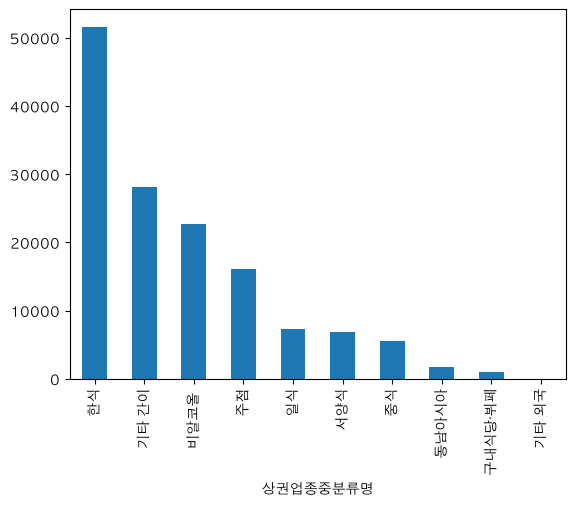

In [43]:
df.loc[ df['상권업종대분류명'] == '음식' , '상권업종중분류명'].value_counts().plot(kind='bar')

<Axes: ylabel='상권업종중분류명'>

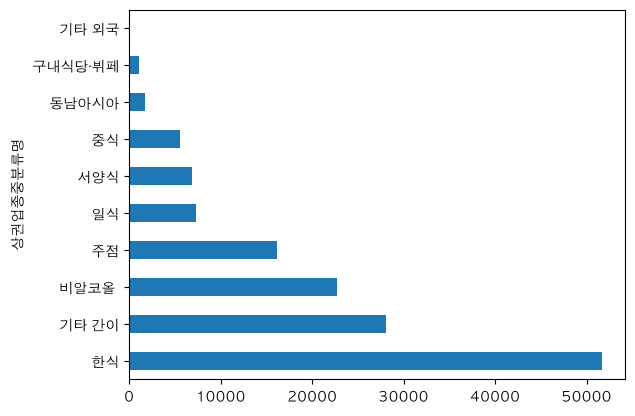

In [44]:
df.loc[ df['상권업종대분류명'] == '음식' , '상권업종중분류명'].value_counts().plot(kind='barh')

<Axes: xlabel='count', ylabel='상권업종중분류명'>

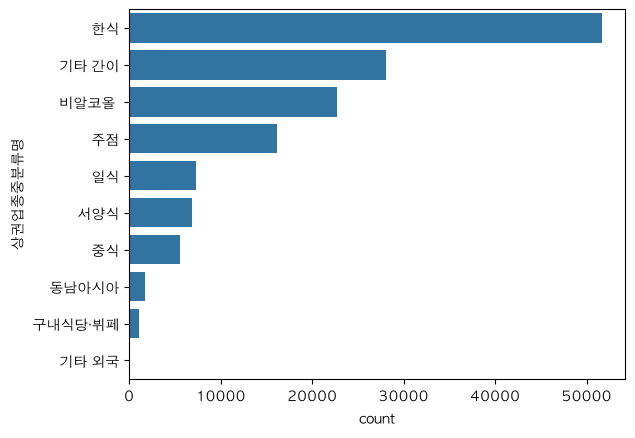

In [45]:
sns.countplot(data=df_food, y='상권업종중분류명',
              order=df_food['상권업종중분류명'].value_counts().index )

---
## 6단계: 카페 TOP 10 브랜드 분석

음식의 소분류명 중 '카페' 업종에서 어떤 브랜드가 가장 많은지 분석합니다.

In [46]:
df_coffee = df[ df['상권업종소분류명'] == '카페' ]
top10 = df_coffee['상호명'].value_counts().head(10).index
top10

Index(['스타벅스', '메가엠지씨커피', '투썸플레이스', '이디야', '이디야커피', '매머드익스프레스', '컴포즈커피', '더벤티',
       '공차', '백억커피'],
      dtype='str', name='상호명')

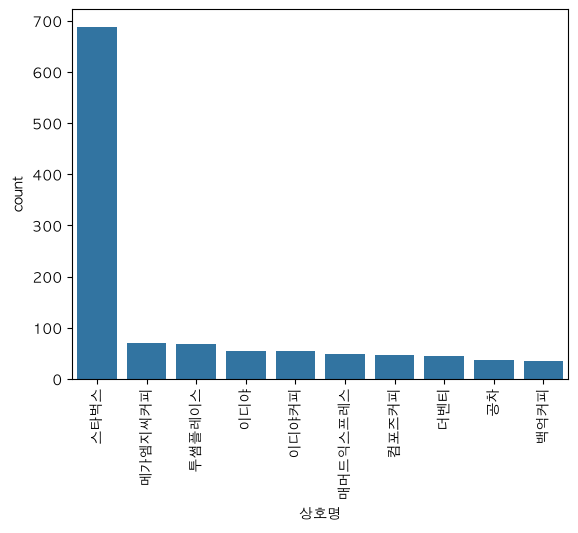

In [47]:
sns.countplot(data=df_coffee[ df_coffee['상호명'].isin(top10)], x='상호명',
              order=top10 )
plt.xticks(rotation=90)
plt.show()

In [48]:
df_coffee['상호명'].value_counts().head(10)

상호명
스타벅스        688
메가엠지씨커피      71
투썸플레이스       69
이디야          55
이디야커피        55
매머드익스프레스     49
컴포즈커피        47
더벤티          44
공차           37
백억커피         35
Name: count, dtype: int64

문제 : 투썸플레이스 와 메가엠지씨커피 

In [49]:
df_coffee['상호명'].str.contains('투썸플레이스')

9         False
17        False
21        False
33         True
35        False
          ...  
553971    False
553979    False
554045    False
554048    False
554085    False
Name: 상호명, Length: 22739, dtype: bool

In [50]:
df_ts = df_coffee[ df_coffee['상호명'].str.contains('투썸플레이스') ].copy()

In [51]:
len(df_ts)

352

In [52]:
df_mega = df_coffee[ df_coffee['상호명'].str.contains('메가엠지씨커피') ].copy()

In [53]:
len(df_mega)

945

In [54]:
df_ts['시군구명'].value_counts()

시군구명
강남구     45
중구      30
서초구     30
송파구     26
강서구     24
마포구     21
영등포구    14
성동구     12
강동구     12
구로구     12
노원구     11
양천구     11
금천구     11
은평구     11
서대문구    10
종로구     10
광진구     10
성북구      9
용산구      8
중랑구      8
동대문구     8
강북구      7
관악구      7
도봉구      3
동작구      2
Name: count, dtype: int64

In [55]:
df_mega['시군구명'].value_counts()

시군구명
강남구     81
송파구     59
영등포구    53
강서구     51
서초구     49
마포구     47
강동구     43
노원구     41
동대문구    40
구로구     40
중구      39
성북구     38
관악구     37
양천구     33
은평구     33
광진구     33
종로구     31
중랑구     30
금천구     28
성동구     27
서대문구    27
강북구     25
도봉구     25
동작구     18
용산구     17
Name: count, dtype: int64

In [56]:
df_compare=pd.DataFrame({
                        '투썸': df_ts['시군구명'].value_counts(),
                        '메가': df_mega['시군구명'].value_counts()
                        })
df_compare

,투썸,메가
시군구명,,
강남구,45,81
강동구,12,43
강북구,7,25
강서구,24,51
관악구,7,37
광진구,10,33
구로구,12,40
금천구,11,28
노원구,11,41


In [57]:
df_compare.sum()

투썸    352
메가    945
dtype: int64

In [58]:
df_compare.sort_values('메가', ascending=False)

,투썸,메가
시군구명,,
강남구,45,81
송파구,26,59
영등포구,14,53
강서구,24,51
서초구,30,49
마포구,21,47
강동구,12,43
노원구,11,41
구로구,12,40


<Axes: xlabel='시군구명'>

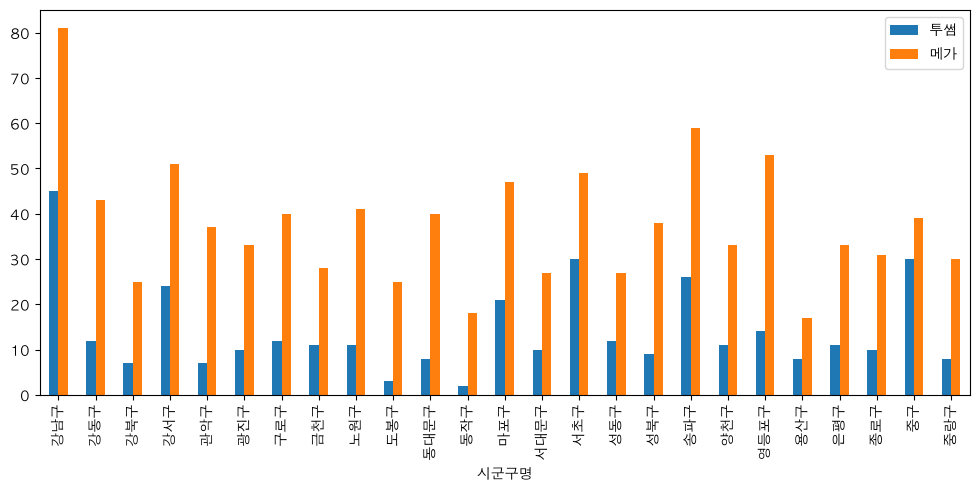

In [59]:
df_compare.plot(kind='bar', figsize=(12, 5))

In [60]:
df_ts[['경도', '위도']].head()

,경도,위도
33,126.994185,37.534228
57,126.983373,37.565275
262,127.057717,37.509959
439,126.991692,37.564231
454,127.034040,37.599356


In [61]:
df_mega[['경도', '위도']].head()

,경도,위도
4109,127.025276,37.500852
4123,126.920011,37.553735
4150,127.123736,37.509755
4213,126.924241,37.556197
4273,127.022055,37.508728


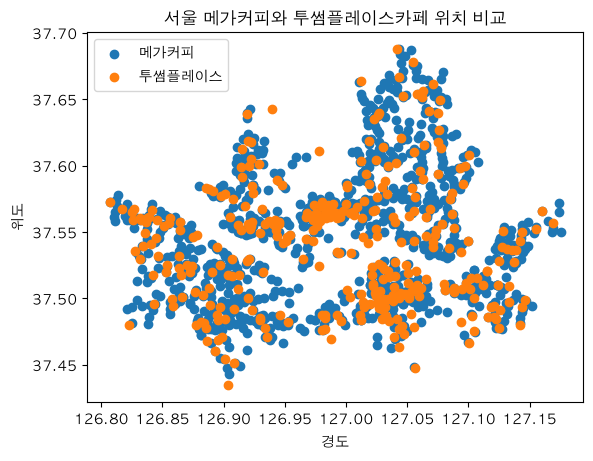

In [62]:
plt.scatter( df_mega['경도'], df_mega['위도'], label='메가커피' )
plt.scatter( df_ts['경도'], df_ts['위도'], label='투썸플레이스' )
plt.legend()
plt.title('서울 메가커피와 투썸플레이스카페 위치 비교')
plt.xlabel('경도')
plt.ylabel('위도')
plt.show()

In [63]:
df_ts['브랜드'] = '투썸플레이스'

In [64]:
df_mega['브랜드'] = '메가커피'

In [65]:
df_ts.head(2)

,상가업소번호,상호명,상권업종대분류명,상권업종중분류명,상권업종소분류명,시군구명,행정동명,법정동명,경도,위도,브랜드
33,MA0106202201A1168632,투썸플레이스,음식,비알코올,카페,용산구,이태원1동,이태원동,126.994185,37.534228,투썸플레이스
57,MA0106202201A1168626,투썸플레이스을지로입구역점,음식,비알코올,카페,중구,명동,을지로2가,126.983373,37.565275,투썸플레이스


In [66]:
df_mega.head(2)

,상가업소번호,상호명,상권업종대분류명,상권업종중분류명,상권업종소분류명,시군구명,행정동명,법정동명,경도,위도,브랜드
4109,MA0106202207A0036967,메가엠지씨커피강남,음식,비알코올,카페,서초구,서초4동,서초동,127.025276,37.500852,메가커피
4123,MA0106202207A0036969,메가엠지씨커피홍대,음식,비알코올,카페,마포구,서교동,서교동,126.920011,37.553735,메가커피


In [67]:
df_all  =  pd.concat( [  df_ts , df_mega  ])
df_all

,상가업소번호,상호명,상권업종대분류명,상권업종중분류명,상권업종소분류명,시군구명,행정동명,법정동명,경도,위도,브랜드
33,MA0106202201A1168632,투썸플레이스,음식,비알코올,카페,용산구,이태원1동,이태원동,126.994185,37.534228,투썸플레이스
57,MA0106202201A1168626,투썸플레이스을지로입구역점,음식,비알코올,카페,중구,명동,을지로2가,126.983373,37.565275,투썸플레이스
262,MA0106202201A1168583,투썸플레이스삼성도심,음식,비알코올,카페,강남구,삼성1동,삼성동,127.057717,37.509959,투썸플레이스
439,MA0106202201A1168587,투썸플레이스KT&G을지로,음식,비알코올,카페,중구,을지로동,초동,126.991692,37.564231,투썸플레이스
454,MA0106202201A1168609,투썸플레이스,음식,비알코올,카페,성북구,종암동,종암동,127.034040,37.599356,투썸플레이스
...,...,...,...,...,...,...,...,...,...,...,...
553432,MA0101202601A0039040,메가엠지씨커피서울숲리버포레점,음식,비알코올,카페,성동구,성수1가2동,성수동1가,127.043817,37.549375,메가커피
553507,MA0101202604A0036584,메가엠지씨커피서울은평,음식,비알코올,카페,은평구,응암2동,응암동,126.922924,37.593245,메가커피
553583,MA0101202602A0013551,메가엠지씨커피삼성리저브점,음식,비알코올,카페,강남구,삼성2동,삼성동,127.055476,37.508086,메가커피
553720,MA0101202602A0011224,메가엠지씨커피용산아스테리움점,음식,비알코올,카페,용산구,한강로동,한강로2가,126.968855,37.527358,메가커피


<Axes: xlabel='경도', ylabel='위도'>

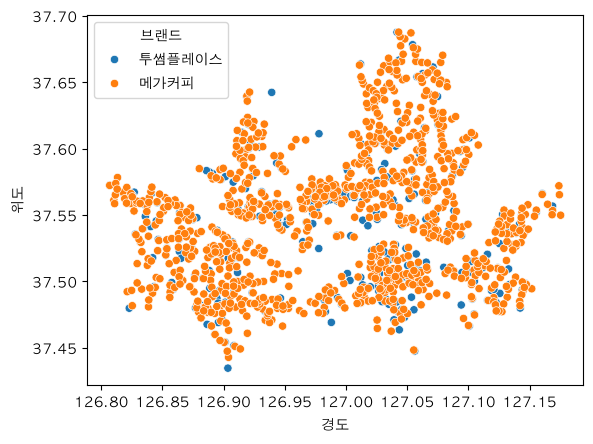

In [68]:
sns.scatterplot(data=df_all, x='경도', y='위도', hue='브랜드')

## folium 라이브러리 설치하기

In [69]:
!pip install folium

In [70]:
import folium

In [71]:
df_mega.head()

,상가업소번호,상호명,상권업종대분류명,상권업종중분류명,상권업종소분류명,시군구명,행정동명,법정동명,경도,위도,브랜드
4109,MA0106202207A0036967,메가엠지씨커피강남,음식,비알코올,카페,서초구,서초4동,서초동,127.025276,37.500852,메가커피
4123,MA0106202207A0036969,메가엠지씨커피홍대,음식,비알코올,카페,마포구,서교동,서교동,126.920011,37.553735,메가커피
4150,MA0106202207A0036966,메가엠지씨커피방이역점,음식,비알코올,카페,송파구,방이1동,방이동,127.123736,37.509755,메가커피
4213,MA0106202207A0036970,메가엠지씨커피홍대입구역점,음식,비알코올,카페,마포구,서교동,동교동,126.924241,37.556197,메가커피
4273,MA0106202207A0036972,메가엠지씨커피논현,음식,비알코올,카페,서초구,반포1동,반포동,127.022055,37.508728,메가커피


In [72]:
mega = df_mega.reset_index(drop=True)

In [73]:
mega.head()

,상가업소번호,상호명,상권업종대분류명,상권업종중분류명,상권업종소분류명,시군구명,행정동명,법정동명,경도,위도,브랜드
0,MA0106202207A0036967,메가엠지씨커피강남,음식,비알코올,카페,서초구,서초4동,서초동,127.025276,37.500852,메가커피
1,MA0106202207A0036969,메가엠지씨커피홍대,음식,비알코올,카페,마포구,서교동,서교동,126.920011,37.553735,메가커피
2,MA0106202207A0036966,메가엠지씨커피방이역점,음식,비알코올,카페,송파구,방이1동,방이동,127.123736,37.509755,메가커피
3,MA0106202207A0036970,메가엠지씨커피홍대입구역점,음식,비알코올,카페,마포구,서교동,동교동,126.924241,37.556197,메가커피
4,MA0106202207A0036972,메가엠지씨커피논현,음식,비알코올,카페,서초구,반포1동,반포동,127.022055,37.508728,메가커피


In [74]:
mega['위도'][0]

np.float64(37.5008521391035)

In [75]:
mega['경도'][0]

np.float64(127.025275817404)

In [76]:
map  = folium.Map(location= [ mega['위도'][0] ,    mega['경도'][0] ],
                  tiles='https://mt1.google.com/vt/lyrs=m&x={x}&y={y}&z={z}&hl=ko',
                  attr='Google' )
map

In [77]:
mega['법정동명'][0]

'서초동'

In [78]:
folium.Marker(location=[  mega['위도'][0] ,    mega['경도'][0]], 
              popup=[mega['법정동명'][0] ] ).add_to(map)

In [79]:
map

In [80]:
for i in range(len(mega)):
    folium.Marker([mega['위도'][i], mega['경도'][i]]
              ,tooltip=mega['법정동명'][i]).add_to(map)

In [81]:
map

여러분 오늘 공부하면서 어떠했나요       
중간고사 기간 앞이라 수업의 양은 조금 줄였으나 새로운 내용들이 있었어요        
이러한 것도 있구나 하고 **경험하는 마음** 으로 공부하면 됩니다       
우리는 중간고사, 기말고사는 보지 않습니다    
**매주 여러분이 하는 실습과 피드백** , **토론활동**, 기말프로젝트로 평가합니다       
즉 **매주 실습을 성실히**  하시면 되겠습니다     
그럼 **아래의 셀에 어떻게 공부하였는지** 저에게 전해주세요 

이번 주에는 loc와 iloc를 처음 배웠는데, 둘 다 데이터를 고르는 방법이라 처음에는 차이가 잘 안 느껴졌습니다. 그런데 loc[0:3]은 4줄, iloc[0:3]은 3줄이 나오는 것을 직접 실행해보고 나서야 끝 값을 포함하는지가 다르다는 게 이해되었습니다.
이번에는 공공데이터포털에서 직접 받은 데이터로 해봤는데, 칸이 39개나 되어서 필요한 열만 골라 쓰는 단계가 왜 있는지 알게 되었습니다. 또 수업 데이터에서는 거의 안 보이던 스타벅스가 카페 1위(688곳)로 나와서 신기했습니다.
카페 TOP 10에서 '이디야'와 '이디야커피'가 따로 나오는 것을 보고 지난주 토론에서 편의점 브랜드 이름이 제각각이었던 것이 떠올랐습니다. 그래서 메가커피도 이름에 '메가엠지씨커피'가 들어간 곳으로 세어봤더니 71곳이 아니라 945곳이나 되어서 놀랐습니다.
마지막에 folium으로 실제 지도 위에 메가커피 위치가 찍히는 것을 보니 지금까지 그린 그래프와는 또 다르게 재미있었습니다!
